In [99]:
import socket
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import time

In [100]:
# --- CIFAR-10 Classes ---
cifar10_classes = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer", 
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

In [106]:
class HardwareCNN(nn.Module):
    def __init__(self):
        super(HardwareCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2) # 32 -> 16 -> 8
        
        self.fc1 = nn.Linear(32 * 8 * 8, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(-1, 32 * 8 * 8)
        
        x = self.fc1(x)
        return x


In [102]:
transform = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.Grayscale(num_output_channels=1),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))])

trainset = torchvision.datasets.CIFAR10(root='../data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=32, shuffle=True) 

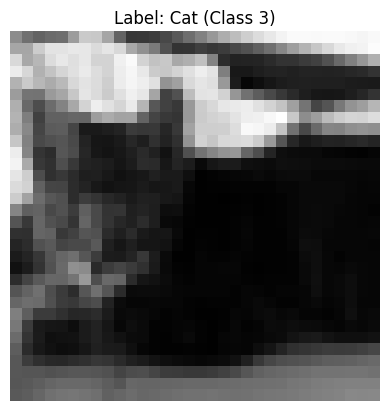

In [103]:
img_tensor, label_idx = trainset[9]

img_denorm = img_tensor * 0.5 + 0.5

img_np = img_denorm.squeeze(0).numpy()

plt.imshow(img_np, cmap='gray')
plt.title(f"Label: {cifar10_classes[label_idx]} (Class {label_idx})")
plt.axis('off')
plt.show()

In [107]:
model = HardwareCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training hardware-accurate model...")
model.train()

epochs = 10
for epoch in range(epochs):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        if i % 200 == 199:
            print(f"Epoch {epoch+1} | Batch {i+1} | Loss: {running_loss / 200:.3f}")
            running_loss = 0.0

print("Finished Training. Saving weights...")
torch.save(model.state_dict(), "model_weights.pth")

Training hardware-accurate model...
Epoch 1 | Batch 200 | Loss: 2.011
Epoch 1 | Batch 400 | Loss: 1.685
Epoch 1 | Batch 600 | Loss: 1.543
Epoch 1 | Batch 800 | Loss: 1.466
Epoch 1 | Batch 1000 | Loss: 1.412
Epoch 1 | Batch 1200 | Loss: 1.375
Epoch 1 | Batch 1400 | Loss: 1.330
Epoch 2 | Batch 200 | Loss: 1.252
Epoch 2 | Batch 400 | Loss: 1.228
Epoch 2 | Batch 600 | Loss: 1.228
Epoch 2 | Batch 800 | Loss: 1.213
Epoch 2 | Batch 1000 | Loss: 1.209
Epoch 2 | Batch 1200 | Loss: 1.164
Epoch 2 | Batch 1400 | Loss: 1.177
Epoch 3 | Batch 200 | Loss: 1.095
Epoch 3 | Batch 400 | Loss: 1.115
Epoch 3 | Batch 600 | Loss: 1.109
Epoch 3 | Batch 800 | Loss: 1.098
Epoch 3 | Batch 1000 | Loss: 1.087
Epoch 3 | Batch 1200 | Loss: 1.099
Epoch 3 | Batch 1400 | Loss: 1.063
Epoch 4 | Batch 200 | Loss: 1.002
Epoch 4 | Batch 400 | Loss: 1.005
Epoch 4 | Batch 600 | Loss: 1.011
Epoch 4 | Batch 800 | Loss: 1.018
Epoch 4 | Batch 1000 | Loss: 1.024
Epoch 4 | Batch 1200 | Loss: 1.011
Epoch 4 | Batch 1400 | Loss: 1.009


In [108]:
def main():
    # Load the 32x32 model and set to evaluation mode
    model = HardwareCNN()  # Or whatever your 32x32 model class is named
    # Optional: If you saved trained weights, load them here:
    model.load_state_dict(torch.load("model_weights.pth"))

    model.eval()

    # --- Network Configuration ---
    UDP_IP = "0.0.0.0"  # Listen on all local interfaces (or your specific PC IP)
    PORT = 8080

    sock = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
    sock.bind((UDP_IP, PORT))
    print(f"PC Inference Server listening for UDP packets on port {PORT}...")

    # 32x32 pixels * 2 bytes (int16) = 2048 bytes total per frame
    EXPECTED_BYTES = 32 * 32 * 2 

    frame_count = 0
    last_print_time = time.time()

    try:
        while True:
            # Expecting 2048 bytes for a 32x32 int16 frame
            # Using 4096 buffer size so it safely captures the payload chunks
            data, addr = sock.recvfrom(4096)
            if len(data) != EXPECTED_BYTES:
                continue

            frame_count += 1

           # 1. Reconstruct the 32x32 numpy array from bytes
            img_array = np.frombuffer(data, dtype=np.int16).reshape((32, 32))

            # 2. Convert to PyTorch Tensor AND scale to [-1.0, 1.0]
            # Since the Pi sent values from -127 to +128, dividing by 127.0 maps it perfectly
            tensor_img = torch.tensor(img_array, dtype=torch.float32) / 127.0
            tensor_img = tensor_img.unsqueeze(0).unsqueeze(0)

            # --- ADD THIS SANITY CHECK ---
            # if frame_count % 10 == 0:
            #    print(f"DEBUG - Tensor Mean: {tensor_img.mean().item():.3f}, Std Dev: {tensor_img.std().item():.3f}")

            # 3. Run Inference through the PyTorch model
            with torch.no_grad():
                outputs = model(tensor_img)
                probabilities = torch.softmax(outputs, dim=1)
                predicted_class = torch.argmax(probabilities, dim=1).item()

            # 4. Time-Gated Print Logic (Every 1 second)
            current_time = time.time()
            if (current_time - last_print_time) >= 1:
                print(f"\n========================================")
                print(f"Processed Frame {frame_count} (32x32)")
                print(f"--- PyTorch Live Scoreboard ---")
                for i in range(10):
                    marker = "->" if i == predicted_class else "  "
                    score_label = "(WINNER)" if i == predicted_class else ""
                    print(f" {marker} {cifar10_classes[i]:<10} : {probabilities[0][i].item():.2f} {score_label}")
                print(f"========================================")
                last_print_time = current_time

    except KeyboardInterrupt:
        print("\nStopping PC server.")
    finally:
        sock.close()

main()

PC Inference Server listening for UDP packets on port 8080...

Processed Frame 31 (32x32)
--- PyTorch Live Scoreboard ---
    Airplane   : 0.00 
    Automobile : 0.00 
 -> Bird       : 0.31 (WINNER)
    Cat        : 0.20 
    Deer       : 0.09 
    Dog        : 0.30 
    Frog       : 0.00 
    Horse      : 0.07 
    Ship       : 0.02 
    Truck      : 0.00 

Processed Frame 62 (32x32)
--- PyTorch Live Scoreboard ---
    Airplane   : 0.00 
    Automobile : 0.00 
    Bird       : 0.25 
    Cat        : 0.25 
    Deer       : 0.09 
 -> Dog        : 0.30 (WINNER)
    Frog       : 0.00 
    Horse      : 0.07 
    Ship       : 0.03 
    Truck      : 0.01 

Processed Frame 93 (32x32)
--- PyTorch Live Scoreboard ---
    Airplane   : 0.00 
    Automobile : 0.00 
    Bird       : 0.28 
    Cat        : 0.22 
    Deer       : 0.09 
 -> Dog        : 0.30 (WINNER)
    Frog       : 0.00 
    Horse      : 0.08 
    Ship       : 0.03 
    Truck      : 0.01 

Processed Frame 124 (32x32)
--- PyTorch Liv